In [40]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Annotated

from langchain_google_genai import ChatGoogleGenerativeAI
from dotenv import load_dotenv

load_dotenv()
model = ChatGoogleGenerativeAI(
    model="gemini-2.5-flash"
)

In [41]:
class BlogState(TypedDict):
    title: str
    outline: str
    content: str
    score: Annotated[int, ..., "A numeric score strictly between 1 and 10"]

In [42]:
# from pydantic import BaseModel, Field

# class BlogState(BaseModel):
#     title: str
#     outline: str
#     content: str
#     score: int = Field(
#         ...,
#         ge=1,
#         le=10,
#         description="A numeric score strictly between 1 and 10"
#     )

In [43]:
def create_outline(state: BlogState) -> BlogState:
    title = state['title']

    # call llm gen outline
    prompt = f'Generate a detailed outline for a blog on the topic - {title}'
    outline = model.invoke(prompt).content

    # update state
    state['outline'] = outline

    return state

In [44]:
def create_blog(state: BlogState) -> BlogState:
    title = state['title']
    outline = state['outline']

    prompt = f'Write a detailed blog on the title - {title} using the follwing outline \n {outline} in 100 words'

    content = model.invoke(prompt).content

    state['content'] = content

    return state

In [45]:
def evaluate_blog(state: BlogState) -> BlogState:
    title = state['title']
    outline = state['outline']
    content = state['content']

    prompt = f'Evaluate this blog {content} on the title - {title} and the follwing outline \n {outline} and rate between  0 -10, do not return str always return int '

    content = model.invoke(prompt).content

    state['score'] = content

    return state

In [46]:
graph = StateGraph(BlogState)

#nodes
graph.add_node('create_outline', create_outline)
graph.add_node('create_blog', create_blog)
graph.add_node('evaluate_blog', evaluate_blog)

#edges

graph.add_edge(START, 'create_outline')
graph.add_edge('create_outline', 'create_blog')
graph.add_edge('create_blog', 'evaluate_blog')
graph.add_edge('evaluate_blog', END)


workflow = graph.compile()

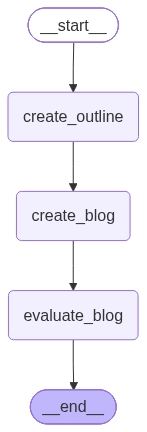

In [47]:
from IPython.display import Image
Image(workflow.get_graph().draw_mermaid_png())

In [48]:
initial_state = {'title' : 'AI in india'}
final_state = workflow.invoke(initial_state)
final_state

{'title': 'AI in india',
 'outline': 'Okay, here\'s a detailed outline for a blog post on "AI in India," designed to be engaging, informative, and comprehensive.\n\n---\n\n## Blog Title Ideas:\n\n*   AI in India: Unlocking the Next Digital Revolution\n*   From Bangalore to Bharat: The Rise of AI in India\n*   India\'s AI Journey: Potential, Pitfalls, and the Path Forward\n*   The Elephant in the AI Room: How India is Shaping the Future of Artificial Intelligence\n*   Beyond the Hype: A Deep Dive into AI\'s Impact on India\n\n---\n\n## Blog Outline: AI in India\n\n**Target Audience:** Tech enthusiasts, policymakers, investors, students, general public interested in India\'s digital transformation.\n\n**Tone:** Informative, optimistic but balanced, slightly investigative, forward-looking.\n\n**Keywords:** AI India, Artificial Intelligence India, Indian AI startups, NITI Aayog AI, Digital India AI, AI in healthcare India, AI in agriculture India, Indian tech talent, AI policy India.\n\n--